# Student Dropout Prediction — Data Exploration

## Objective
Explore a real-world student academic success dataset
to understand its structure, features, target variable,
data quality, and suitability for machine learning.

**Dataset:** UCI ML Repository — ID 697
**Task:** Multiclass Classification

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [4]:
#loading the dataset
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
#inspecting columns
print("Total columns:", len(df.columns))

for index, column in enumerate(df.columns, start=1):
    print(f"{index:02d}. {column}")

Total columns: 37
01. Marital status
02. Application mode
03. Application order
04. Course
05. Daytime/evening attendance	
06. Previous qualification
07. Previous qualification (grade)
08. Nacionality
09. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Curricular units 2nd sem (credited)
29. Curricular units 2nd sem (enrolled)
30. Curricular units 2nd sem (evaluations)
31. Curricular units 2nd sem (approved)
32. Curricular units 2nd sem (grade)
33. Curricular units 2nd sem (without evaluations)
34. Unemployment r

In [6]:
#checking data types
df.info()

display(df.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

int64      29
float64     7
str         1
Name: count, dtype: int64

In [7]:
#check m issing values and duplicates
missing_values = df.isnull().sum()

print("Total missing values:")
print(missing_values.sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

display(
    missing_values[missing_values > 0]
        .sort_values(ascending=False)
)

Total missing values:
0

Duplicate rows:
0


Series([], dtype: int64)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Percentage distribution:
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


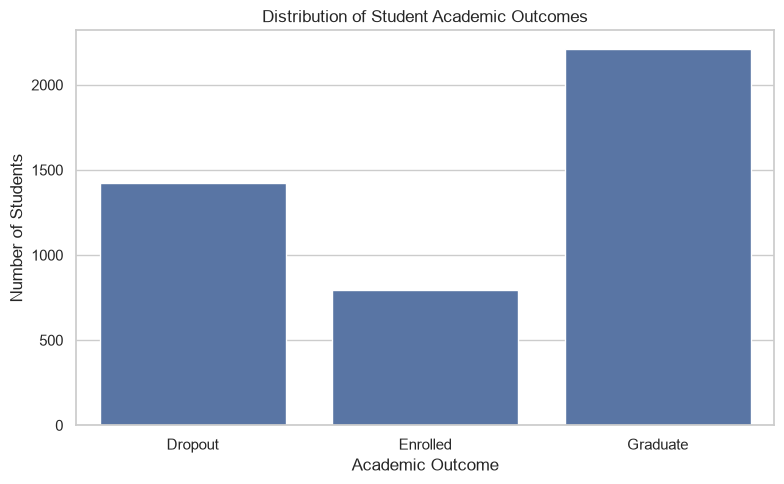

In [ ]:
print(df["Target"].value_counts())

print("\nPercentage distribution:")
print(
    df["Target"].value_counts(normalize=True) * 100
)
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Distribution of Student Academic Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show() # before training the modelwe can visualize the class imbalance as below with below chart

#Observations:
#Since the target classess are imbalanced , when evaluating model performance accuracy only will not be enough. We will need to use other metrics like precision, recall, f1-score and confusion matrix to evaluate the model performance


In [9]:
#Descriptive statistics of the dataset
display(df.describe().T)

print("Number of numerical columns:")
print(df.select_dtypes(include=np.number).shape[1])

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


Number of numerical columns:
36


In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget classes:")
print(df["Target"].unique())

Rows: 4424
Columns: 37
Missing values: 0
Duplicate rows: 0

Target classes:
<ArrowStringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str


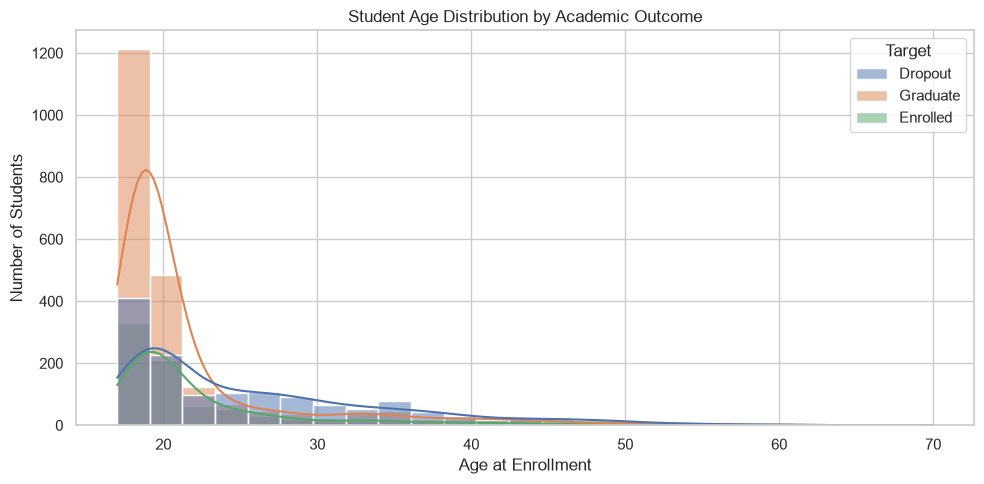

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    hue="Target",
    bins=25,
    kde=True
)

plt.title("Student Age Distribution by Academic Outcome")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

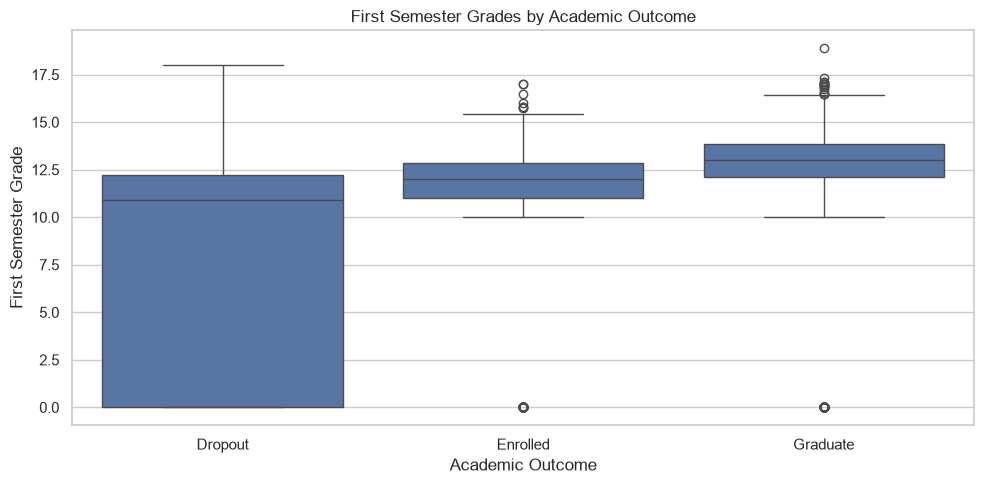

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("First Semester Grades by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("First Semester Grade")

plt.tight_layout()
plt.show()